# HybridMSLATNet on APTOS (clean pipeline)

**Run the cells top to bottom, once.** Needs a **GPU runtime** (it also runs on CPU, but very slowly).

Order: setup (1-3) → imports & config (4-5) → transforms (6) → data + duplicate cleaning (7) → quantum circuit & model (8-10) → loss (11) → model/optimizer (12) → training (13) → test evaluation (14) → curves (15).

**Smoke test first:** in the config cell set `"epochs": 3` and `"tag": "smoke"`, run everything, check there are no errors, then set `"epochs": 50` and `"tag": ""` and run again (the tag keeps the checkpoints of the two runs separate).


## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install timm pennylane pennylane-lightning -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 11.6 MB/s eta 0:00:00


In [ ]:
import os, zipfile

zip_path     = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/APTOS"

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset ready.")

Dataset ready.


## 2. Imports and configuration

In [ ]:
import os, random, hashlib
import numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm import tqdm
import timm
import pennylane as qml
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, roc_auc_score, classification_report, confusion_matrix)

In [ ]:
BASE_PATH = "/content/drive/MyDrive/your folder"
os.makedirs(BASE_PATH + "/checkpoints", exist_ok=True)

SEED = 42          # change to 43, 44 for extra seeds

config = {
    "epochs": 50,
    "batch_size": 32,
    "num_classes": 5,
    "lr_backbone": 1e-4,
    "lr_other": 1e-4,
    "lr_alpha": 1e-2,        # raised so alpha can really move (APTOS gives only ~88 steps per epoch)
    "weight_decay": 0.01,

    # ---- experiment switches: the defaults below are the BASELINE model ----
    "quantum_mode": "circuit",   # "circuit" | "skip" (no circuit, same 8 numbers) | "mlp" (matched classical layer) | "frozen" (random untrained circuit)
    "fixed_alpha": None,         # None = learnable. Or a number (0.0, 0.27, 0.5, 1.0) to fix the mixing weight
    "use_pos_emb": False,        # True = add learned position/scale embeddings to the tokens
    "n_trans_layers": 4,         # Transformer depth

    "tag": "v3",                   # e.g. "smoke" for the quick test run
}

RUN = (f"{config['tag']}_" if config["tag"] else "") + \
      f"{config['quantum_mode']}_a{config['fixed_alpha']}_pe{int(config['use_pos_emb'])}_L{config['n_trans_layers']}_s{SEED}"
print("RUN name:", RUN)

RUN name: v3_circuit_aNone_pe0_L4_s42


## 3. Augmentation
Colour-neutral (no hue shift, no CLAHE, no random erasing); the same preprocessing for every split.

In [ ]:
train_tf = A.Compose([
    A.Resize(256, 256),
    A.RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0)),
    A.HorizontalFlip(),
    A.VerticalFlip(),
    A.Rotate(limit=15),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

val_tf = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

## 4. Data: read APTOS, remove exact duplicates, build loaders
The first run hashes every image (about 1.5 minutes) and saves `aptos_clean_split.csv`; later runs just load that file.

In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ---------- read the three label files ----------
ROOT = "/content/APTOS"
tr = pd.read_csv(f"{ROOT}/train_1.csv"); tr["dir"] = f"{ROOT}/train_images/train_images"
va = pd.read_csv(f"{ROOT}/valid.csv");   va["dir"] = f"{ROOT}/val_images/val_images"
te = pd.read_csv(f"{ROOT}/test.csv");    te["dir"] = f"{ROOT}/test_images/test_images"

print("rows  train/valid/test:", len(tr), len(va), len(te))
print("ids shared train/valid:", len(set(tr.id_code) & set(va.id_code)),
      "| train/test:", len(set(tr.id_code) & set(te.id_code)),
      "| valid/test:", len(set(va.id_code) & set(te.id_code)))

# ---------- remove exact duplicates (cached) ----------
CLEAN_CSV = BASE_PATH + "/aptos_clean_split.csv"
if os.path.exists(CLEAN_CSV):
    clean = pd.read_csv(CLEAN_CSV)
    print("Loaded cleaned split from", CLEAN_CSV)
else:
    pool = pd.concat([tr, va, te]).reset_index(drop=True)
    pool["split"] = ["train"] * len(tr) + ["val"] * len(va) + ["test"] * len(te)
    path_of = lambda r: f"{r['dir']}/{r['id_code']}.png"
    pool["md5"] = [hashlib.md5(open(path_of(r), "rb").read()).hexdigest()
                   for _, r in tqdm(pool.iterrows(), total=len(pool))]

    order = {"train": 0, "val": 1, "test": 2}
    keep, removed_dup, removed_conflict = [], 0, 0
    for h, grp in pool.groupby("md5"):
        if len(grp) == 1:
            keep.append(grp.index[0]); continue
        if grp["diagnosis"].nunique() > 1:          # same photo with different labels -> drop all copies
            removed_conflict += len(grp); continue
        keep.append(grp.assign(o=grp["split"].map(order)).sort_values("o").index[0])   # earliest split wins
        removed_dup += len(grp) - 1

    clean = pool.loc[sorted(keep)]
    print(f"before: {len(pool)} | duplicates removed: {removed_dup} | removed (conflicting labels): {removed_conflict} | after: {len(clean)}")
    clean.to_csv(CLEAN_CSV, index=False)

import cv2
from concurrent.futures import ThreadPoolExecutor
CACHE = "/content/aptos_256"; os.makedirs(CACHE, exist_ok=True)

def cache_one(a):
    src, dst = a
    if not os.path.exists(dst):
        im = cv2.imread(src)
        cv2.imwrite(dst, cv2.resize(im, (256, 256), interpolation=cv2.INTER_AREA))

jobs = [(f"{r['dir']}/{r['id_code']}.png", f"{CACHE}/{r['id_code']}.png") for _, r in clean.iterrows()]
with ThreadPoolExecutor(4) as ex:
    list(tqdm(ex.map(cache_one, jobs), total=len(jobs)))
clean["dir"] = CACHE          # loaders now read the small images (in memory only; the saved CSV is unchanged)
train_df = clean[clean["split"] == "train"]
val_df   = clean[clean["split"] == "val"]
test_df  = clean[clean["split"] == "test"]
for nm, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nm:5s} {len(d):5d}", np.bincount(d["diagnosis"], minlength=5))

# ---------- dataset + loaders ----------
class APTOSDF(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.t = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = np.array(Image.open(os.path.join(r["dir"], r["id_code"] + ".png")).convert("RGB"))
        return self.t(image=img)["image"], int(r["diagnosis"])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)
bs = config["batch_size"]
train_loader = DataLoader(APTOSDF(train_df, train_tf), batch_size=bs, shuffle=True, num_workers=2,
                          pin_memory=True, persistent_workers=True,generator=g, worker_init_fn=seed_worker, drop_last=True)
val_loader   = DataLoader(APTOSDF(val_df,  val_tf), batch_size=bs, shuffle=False, persistent_workers=True,num_workers=2, pin_memory=True)
test_loader  = DataLoader(APTOSDF(test_df, val_tf), batch_size=bs, shuffle=False, persistent_workers=True,num_workers=2, pin_memory=True)

rows  train/valid/test: 2930 366 366
ids shared train/valid: 0 | train/test: 0 | valid/test: 0
Loaded cleaned split from /content/drive/MyDrive/APTOS-Finalkefinal(modified-NEW1)/aptos_clean_split.csv


100%|██████████| 3504/3504 [07:54<00:00,  7.39it/s]

train  2824 [1427  277  756  145  219]
val     341 [172  33  91  20  25]
test    339 [197  28  75  12  27]


## 5. Quantum circuit (8 qubits, 3 layers, data re-uploading, ring CNOT)

In [ ]:
n_qubits = 8
n_layers = 3

dev = qml.device("default.qubit", wires=n_qubits)

def quantum_circuit(inputs, weights):
    for i in range(n_qubits):                       # initial U3 encoding
        qml.U3(inputs[..., i], inputs[..., i], inputs[..., i], wires=i)
    for l in range(n_layers):
        for i in range(n_qubits):                   # data re-uploading
            qml.RY(inputs[..., i], wires=i)
        for i in range(n_qubits):                   # trainable single-qubit rotations (72 parameters in total)
            qml.U3(weights[l][i][0], weights[l][i][1], weights[l][i][2], wires=i)
        for i in range(n_qubits):                   # ring entanglement
            qml.CNOT(wires=[i, (i + 1) % n_qubits])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (n_layers, n_qubits, 3)}
qnode = qml.QNode(quantum_circuit, dev, interface="torch", diff_method="backprop")

In [ ]:
import time
w = {"weights": (n_layers, n_qubits, 3)}
q_old = qml.qnn.TorchLayer(qml.QNode(quantum_circuit, qml.device("lightning.qubit", wires=8), interface="torch", diff_method="adjoint"), w)
q_new = qml.qnn.TorchLayer(qml.QNode(quantum_circuit, qml.device("default.qubit", wires=8), interface="torch", diff_method="backprop"), w)
q_new.load_state_dict(q_old.state_dict())

xin = (torch.rand(32, 8) * 2 - 1) * np.pi
print("max output difference:", (q_old(xin) - q_new(xin)).abs().max().item())      # expect ~1e-6 or smaller

# gradients should also agree
xa = xin.clone().requires_grad_(True); xb = xin.clone().requires_grad_(True)
q_old(xa).sum().backward(); q_new(xb).sum().backward()
print("max input-gradient difference:", (xa.grad - xb.grad).abs().max().item())

t = time.time()
for _ in range(3): q_new(xin.clone().requires_grad_(True)).sum().backward()
print(f"new layer on CPU: {(time.time()-t)/3:.2f} s per batch")

try:
    q_gpu = q_new.to(device); xg = xin.to(device).requires_grad_(True)
    q_gpu(xg).sum().backward(); torch.cuda.synchronize(); t = time.time()
    for _ in range(3): q_gpu(xg).sum().backward()
    torch.cuda.synchronize(); print(f"new layer on GPU: {(time.time()-t)/3:.2f} s per batch")
except Exception as e:
    print("GPU test failed:", type(e).__name__, str(e)[:150])

max output difference: 3.5762786865234375e-07
max input-gradient difference: 1.0132789611816406e-06
new layer on CPU: 0.26 s per batch
GPU test failed: NameError name 'device' is not defined


In [ ]:
class QuantumBranch(nn.Module):
    """256 -> attention gate -> reducer -> 8 angles -> (circuit | control) -> 8 features"""
    def __init__(self, feature_dim=256, mode="circuit"):
        super().__init__()
        self.mode = mode

        self.attn = nn.Sequential(
            nn.Linear(feature_dim, 64), nn.ReLU(), nn.Linear(64, feature_dim)
        )
        self.reducer = nn.Sequential(
            nn.Linear(feature_dim, 256), nn.GELU(), nn.Dropout(0.2),
            nn.Linear(256, 128),         nn.GELU(), nn.Dropout(0.2),
            nn.Linear(128, 64),          nn.GELU(), nn.Dropout(0.2),
            nn.Linear(64, n_qubits)
        )

        if mode in ("circuit", "frozen"):
            self.quantum = qml.qnn.TorchLayer(qnode, weight_shapes)   # a fresh circuit for every model
            if mode == "frozen":                                      # random circuit that is never trained
                for p in self.quantum.parameters():
                    p.requires_grad_(False)
        elif mode == "mlp":                                           # matched classical layer: 8*8 + 8 = 72 parameters
            self.quantum = nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.Tanh())
        elif mode == "skip":                                          # no circuit at all
            self.quantum = None
        else:
            raise ValueError(f"unknown quantum_mode: {mode}")

    def forward(self, x):
        a = torch.softmax(self.attn(x), dim=-1)
        x = x * a
        x = self.reducer(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = torch.tanh(x) * np.pi                       # 8 angles in (-pi, pi)

        if self.mode in ("circuit", "frozen"):
            q_out = self.quantum(x.float())
        elif self.mode == "mlp":
            q_out = self.quantum(x.float() / np.pi)
        else:                                            # "skip": same 8 numbers, scaled to (-1, 1) like the circuit output
            q_out = x.float() / np.pi
        return q_out, x

In [ ]:
class HybridMSLATNet(nn.Module):
    def __init__(self, num_classes=5, embed_dim=256, n_trans_layers=4, use_pos_emb=False,
                 quantum_mode="circuit", fixed_alpha=None):
        super().__init__()

        self.backbone = timm.create_model("efficientnet_b2", pretrained=True, features_only=True)
        feat_dims = [f["num_chs"] for f in self.backbone.feature_info[-3:]]

        self.proj = nn.ModuleList([nn.Linear(feat_dims[i], embed_dim) for i in range(3)])

        # optional learned position / scale embeddings (one vector per token of the concatenated sequence)
        self.pos_emb = None
        if use_pos_emb:
            was_training = self.backbone.training
            self.backbone.eval()
            with torch.no_grad():
                fs = self.backbone(torch.zeros(1, 3, 224, 224))[-3:]
            n_tokens = sum(f.shape[2] * f.shape[3] for f in fs)
            self.backbone.train(was_training)
            self.pos_emb = nn.Parameter(torch.zeros(1, n_tokens, embed_dim))
            nn.init.trunc_normal_(self.pos_emb, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=8, dim_feedforward=embed_dim * 4,
            dropout=0.5, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=n_trans_layers, enable_nested_tensor=False)

        self.pool = nn.Linear(embed_dim, 1)

        self.classical_head = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, 64),        nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

        self.quantum_branch = QuantumBranch(embed_dim, mode=quantum_mode)

        self.fusion_head = nn.Sequential(
            nn.Linear(embed_dim + n_qubits, 256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        self.quantum_head = nn.Sequential(
            nn.Linear(n_qubits, 32), nn.GELU(), nn.Linear(32, num_classes)
        )

        # mixing weight between the classical and the fused prediction
        self.learn_alpha = fixed_alpha is None
        if self.learn_alpha:
            self.alpha = nn.Parameter(torch.tensor(-1.0))               # sigmoid(-1) = 0.269 at the start
        else:
            self.register_buffer("alpha", torch.tensor(float(fixed_alpha)))

    def get_alpha(self):
        return torch.sigmoid(self.alpha) if self.learn_alpha else self.alpha

    def forward(self, x):
        feats = self.backbone(x)[-3:]

        tokens = []
        for i, f in enumerate(feats):
            t = f.flatten(2).transpose(1, 2)          # (B, H*W, C): every spatial position is one token
            tokens.append(self.proj[i](t))
        tokens = torch.cat(tokens, dim=1)
        if self.pos_emb is not None:
            tokens = tokens + self.pos_emb
        tokens = self.transformer(tokens)

        attn = torch.softmax(self.pool(tokens), dim=1)
        pooled = (tokens * attn).sum(dim=1)            # (B, 256)

        classical_logits = self.classical_head(pooled)

        quantum_features, q_input = self.quantum_branch(pooled)
        fusion_logits  = self.fusion_head(torch.cat([pooled, quantum_features], dim=1))
        quantum_logits = self.quantum_head(quantum_features)

        alpha = self.get_alpha()
        out = (1 - alpha) * classical_logits + alpha * fusion_logits

        return out, classical_logits, quantum_logits, pooled, attn, q_input

## 6. Losses
Focal loss with label smoothing, per-sample severity weight (x1.5 for grades 3-4), and a corrected ordinal (cumulative-probability) loss.

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2, smoothing=0.05):
        super().__init__()
        self.gamma, self.smoothing = gamma, smoothing

    def forward(self, logits, targets, reduction="mean"):
        logits = logits.float()
        K = logits.size(1)
        with torch.no_grad():
            t = torch.full_like(logits, self.smoothing / (K - 1))
            t.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        ce = -(t * F.log_softmax(logits, dim=1)).sum(dim=1)
        loss = (1 - torch.exp(-ce)) ** self.gamma * ce
        return loss if reduction == "none" else loss.mean()

def ordinal_loss(logits, targets):
    # P(grade <= j) must be 0 for j < true grade and 1 for j >= true grade
    cum = torch.cumsum(torch.softmax(logits.float(), dim=1), dim=1)
    idx = torch.arange(cum.size(1), device=cum.device).unsqueeze(0)
    tgt = (idx >= targets.unsqueeze(1)).float()
    return F.mse_loss(cum, tgt)

def compute_total_loss(hybrid_logits, classical_logits, quantum_logits, targets, focal_fn):
    w = torch.ones_like(targets, dtype=torch.float32)
    w[targets >= 3] = 1.5                                            # per-sample severity weight
    hybrid_loss    = (w * focal_fn(hybrid_logits, targets, "none")).mean()
    classical_loss = focal_fn(classical_logits, targets)
    quantum_loss   = focal_fn(quantum_logits, targets)
    ord_loss       = ordinal_loss(hybrid_logits, targets)
    return hybrid_loss + 0.2 * quantum_loss + 0.3 * classical_loss + 0.1 * ord_loss

## 7. Create model, optimizer, scheduler

In [ ]:
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| mixed precision:", use_amp)

set_seed(SEED)                                   # same starting weights for the same seed
model = HybridMSLATNet(
    n_trans_layers=config["n_trans_layers"],
    use_pos_emb=config["use_pos_emb"],
    quantum_mode=config["quantum_mode"],
    fixed_alpha=config["fixed_alpha"],
).to(device)

criterion = FocalLoss(gamma=2, smoothing=0.05)

backbone_params = list(model.backbone.parameters())
bb_ids = {id(p) for p in backbone_params}
alpha_params = [model.alpha] if model.learn_alpha else []
al_ids = {id(p) for p in alpha_params}
other_params = [p for p in model.parameters()
                if p.requires_grad and id(p) not in bb_ids and id(p) not in al_ids]

groups = [{"params": backbone_params, "lr": config["lr_backbone"]},
          {"params": other_params,    "lr": config["lr_other"]}]
if alpha_params:
    groups.append({"params": alpha_params, "lr": config["lr_alpha"], "weight_decay": 0.0})
optimizer = torch.optim.AdamW(groups, weight_decay=config["weight_decay"])

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
warmup    = LinearLR(optimizer, start_factor=0.1, total_iters=5)
cosine    = CosineAnnealingLR(optimizer, T_max=max(1, config["epochs"] - 5))
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[5])

# parameter counts (useful for the complexity table in the paper)
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_quant = sum(p.numel() for p in model.quantum_branch.quantum.parameters()) if model.quantum_branch.quantum is not None else 0
print(f"parameters: total {n_total/1e6:.2f} M | trainable {n_train/1e6:.2f} M | quantum/control layer {n_quant}")

device: cpu | mixed precision: False


model.safetensors: reconstructing file:   0%|          |  0.00B / 36.8MB            

model.safetensors: downloading bytes:           |  0.00B            

parameters: total 10.75 M | trainable 10.75 M | quantum/control layer 72


In [ ]:
best_path = f"{BASE_PATH}/checkpoints/best_{RUN}.pth"
ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
print("loaded epoch", ck["epoch"] + 1, "| alpha", round(ck["alpha"], 3))      # should say 35 and 0.829

@torch.no_grad()
def eval_head(loader, idx):          # 0 = final blend, 1 = classical head only, 2 = circuit/control features only
    model.eval(); P, Yy = [], []
    for imgs, labels in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(imgs.to(device, non_blocking=True))[idx]
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Yy.append(labels.numpy())
    P = np.concatenate(P).astype(np.float64); P /= P.sum(1, keepdims=True)
    Yy = np.concatenate(Yy); pr = P.argmax(1)
    return dict(acc=accuracy_score(Yy, pr), f1=f1_score(Yy, pr, average="macro"),
                qwk=cohen_kappa_score(Yy, pr, weights="quadratic"), auc=roc_auc_score(Yy, P, multi_class="ovr"))

for name, idx in [("final blend", 0), ("classical head only", 1), ("circuit features only", 2)]:
    print(f"{name:30s}", {k: round(float(v), 4) for k, v in eval_head(test_loader, idx).items()})

loaded epoch 35 | alpha 0.829


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


final blend                    {'acc': 0.8407, 'f1': 0.6017, 'qwk': 0.8759, 'auc': 0.9316}
classical head only            {'acc': 0.8407, 'f1': 0.6017, 'qwk': 0.8759, 'auc': 0.9385}
circuit features only          {'acc': 0.7876, 'f1': 0.3338, 'qwk': 0.7848, 'auc': 0.8768}


## 8. Training
Each epoch: train, then score on the **validation** set. The checkpoint with the best validation QWK is kept in `best_<RUN>.pth`. The test set is not touched here.

In [ ]:
best_path = f"{BASE_PATH}/checkpoints/best_{RUN}.pth"     # best validation QWK (never overwritten by 'last')
last_path = f"{BASE_PATH}/checkpoints/last_{RUN}.pth"     # resume point

@torch.no_grad()
def evaluate(loader):
    model.eval(); P, Y = [], []
    for imgs, labels in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(imgs.to(device, non_blocking=True))[0]
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Y.append(labels.numpy())
    P = np.concatenate(P).astype(np.float64); P = P / P.sum(1, keepdims=True)
    Y = np.concatenate(Y); pred = P.argmax(1)
    m = dict(acc=accuracy_score(Y, pred),
             f1=f1_score(Y, pred, average="macro"),
             prec=precision_score(Y, pred, average="macro", zero_division=0),
             rec=recall_score(Y, pred, average="macro", zero_division=0),
             qwk=cohen_kappa_score(Y, pred, weights="quadratic"),
             auc=roc_auc_score(Y, P, multi_class="ovr", average="macro"))
    return m, P, Y, pred

start_epoch, best_qwk, log = 0, -1.0, []
if os.path.exists(last_path):
    ck = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["opt"]); scheduler.load_state_dict(ck["sched"])
    start_epoch, best_qwk, log = ck["epoch"] + 1, ck["best_qwk"], ck["log"]
    print(f"Resuming from epoch {start_epoch}, best val QWK {best_qwk:.4f}")

scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(start_epoch, config["epochs"]):
    model.train(); run_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out, cl, ql = model(imgs)[:3]
            loss = compute_total_loss(out, cl, ql, labels, criterion)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        run_loss += loss.item()
    scheduler.step()

    vm, *_ = evaluate(val_loader)
    alpha = float(model.get_alpha())
    log.append(dict(epoch=epoch + 1, train_loss=run_loss / len(train_loader), alpha=alpha,
                    **{f"val_{k}": v for k, v in vm.items()}))
    print(f"Ep {epoch+1:03d} loss {log[-1]['train_loss']:.4f} | val acc {vm['acc']:.4f} f1 {vm['f1']:.4f} "
          f"QWK {vm['qwk']:.4f} AUC {vm['auc']:.4f} | alpha {alpha:.3f}")

    if vm["qwk"] > best_qwk:
        best_qwk = vm["qwk"]
        torch.save({"epoch": epoch, "model": model.state_dict(), "alpha": alpha, "val": vm}, best_path)
        print("   saved best")
    torch.save({"epoch": epoch, "model": model.state_dict(), "opt": optimizer.state_dict(),
                "sched": scheduler.state_dict(), "best_qwk": best_qwk, "log": log}, last_path)

pd.DataFrame(log).to_csv(f"{BASE_PATH}/train_log_{RUN}.csv", index=False)
print("Training finished. Best validation QWK:", round(best_qwk, 4))

/tmp/ipykernel_28838/1178920089.py:46: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  alpha = float(model.get_alpha())


Ep 001 loss 1.5218 | val acc 0.5044 f1 0.1341 QWK 0.0000 AUC 0.6696 | alpha 0.288
   saved best
Ep 002 loss 1.3234 | val acc 0.7273 f1 0.3162 QWK 0.7198 AUC 0.8265 | alpha 0.344
   saved best
Ep 003 loss 0.9543 | val acc 0.7566 f1 0.3325 QWK 0.8102 AUC 0.8901 | alpha 0.428
   saved best
Ep 004 loss 0.8262 | val acc 0.7654 f1 0.3668 QWK 0.8193 AUC 0.9137 | alpha 0.475
   saved best
Ep 005 loss 0.7468 | val acc 0.7273 f1 0.4325 QWK 0.8735 AUC 0.9155 | alpha 0.540
   saved best
Ep 006 loss 0.6661 | val acc 0.7683 f1 0.5357 QWK 0.8545 AUC 0.9249 | alpha 0.569
Ep 007 loss 0.6170 | val acc 0.7977 f1 0.5577 QWK 0.8605 AUC 0.9329 | alpha 0.590
Ep 008 loss 0.5514 | val acc 0.8006 f1 0.6478 QWK 0.9043 AUC 0.9349 | alpha 0.623
   saved best
Ep 009 loss 0.5289 | val acc 0.8270 f1 0.6732 QWK 0.9000 AUC 0.9367 | alpha 0.643
Ep 010 loss 0.4634 | val acc 0.7977 f1 0.6181 QWK 0.8969 AUC 0.9311 | alpha 0.664
Ep 011 loss 0.4330 | val acc 0.8358 f1 0.6727 QWK 0.9044 AUC 0.9336 | alpha 0.678
   saved best


In [ ]:
import time
def sync():
    if device.type == "cuda": torch.cuda.synchronize()

# 1) data loading only
t = time.time()
for i, (x, y) in enumerate(train_loader):
    if i == 5: break
print(f"data loading: {(time.time()-t)/6:.2f} s per batch  (x88 batches = {(time.time()-t)/6*88/60:.1f} min per epoch)")

# 2) quantum layer only, forward + backward
x, y = x.to(device), y.to(device)
qin = ((torch.rand(32, 8, device=device) * 2 - 1) * np.pi).requires_grad_(True)
t = time.time()
for _ in range(3):
    model.quantum_branch.quantum(qin).sum().backward()
sync(); print(f"quantum layer: {(time.time()-t)/3:.2f} s per batch")

# 3) one full training step
model.train(); t = time.time()
for _ in range(3):
    optimizer.zero_grad()
    with torch.autocast(device_type=device.type, enabled=use_amp):
        out, cl, ql = model(x)[:3]
        loss = compute_total_loss(out, cl, ql, y, criterion)
    loss.backward()
sync(); print(f"full step: {(time.time()-t)/3:.2f} s per batch")

data loading: 5.05 s per batch  (x88 batches = 7.4 min per epoch)
quantum layer: 10.45 s per batch
full step: 10.80 s per batch


## 9. Final evaluation on the TEST set
**Run this once**, after training has finished. It loads the best-validation checkpoint.

In [ ]:
ck = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
tm, P, Y, pred = evaluate(test_loader)

print(f"best epoch {ck['epoch']+1} | alpha {ck['alpha']:.3f}")
print({k: round(float(v), 4) for k, v in tm.items()})
names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
print(classification_report(Y, pred, target_names=names, digits=4))
print("confusion matrix (rows = true grade, columns = predicted grade):")
print(confusion_matrix(Y, pred))

# keep everything needed for tables, confidence intervals and plots later
np.savez(f"{BASE_PATH}/test_preds_{RUN}.npz", P=P, Y=Y)
row = dict(run=RUN, best_epoch=ck["epoch"] + 1, alpha=ck["alpha"], **{k: float(v) for k, v in tm.items()})
res_path = f"{BASE_PATH}/results.csv"
pd.DataFrame([row]).to_csv(res_path, mode="a", header=not os.path.exists(res_path), index=False)

best epoch 35 | alpha 0.829
{'acc': 0.8407, 'f1': 0.6017, 'prec': 0.6283, 'rec': 0.5977, 'qwk': 0.8759, 'auc': 0.9313}
               precision    recall  f1-score   support

        No DR     0.9800    0.9949    0.9874       197
         Mild     0.6842    0.4643    0.5532        28
     Moderate     0.7273    0.8533    0.7853        75
       Severe     0.3125    0.4167    0.3571        12
Proliferative     0.4375    0.2593    0.3256        27

     accuracy                         0.8407       339
    macro avg     0.6283    0.5977    0.6017       339
 weighted avg     0.8328    0.8407    0.8318       339

confusion matrix (rows = true grade, columns = predicted grade):
[[196   0   1   0   0]
 [  3  13  10   0   2]
 [  1   4  64   2   4]
 [  0   0   4   5   3]
 [  0   2   9   9   7]]


## 10. Training curves

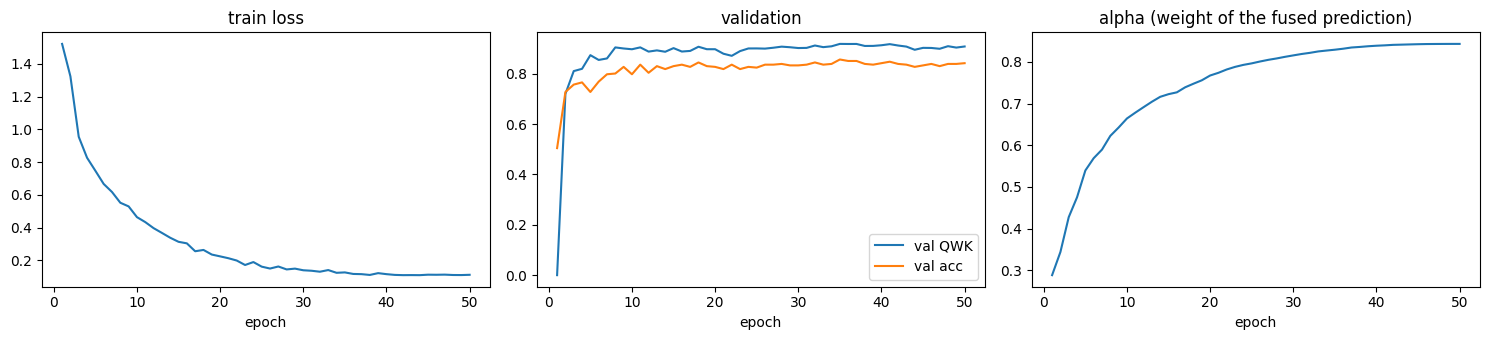

<function matplotlib.pyplot.savefig(*args, **kwargs) -> 'None'>

In [ ]:
import matplotlib.pyplot as plt
lg = pd.read_csv(f"{BASE_PATH}/train_log_{RUN}.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(lg.epoch, lg.train_loss); ax[0].set_title("train loss")
ax[1].plot(lg.epoch, lg.val_qwk, label="val QWK"); ax[1].plot(lg.epoch, lg.val_acc, label="val acc"); ax[1].legend(); ax[1].set_title("validation")
ax[2].plot(lg.epoch, lg.alpha); ax[2].set_title("alpha (weight of the fused prediction)")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()
plt.savefig